In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
df = pd.read_excel('../data/raw/Telco_customer_churn.xlsx')
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

In [5]:

df["Total  Charges"] = df["Total Charges"].fillna(0)


In [6]:

df["Total Charges"].isnull().sum()

np.int64(11)

In [7]:
df["Churn Value"].value_counts(normalize=True)*100

Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64

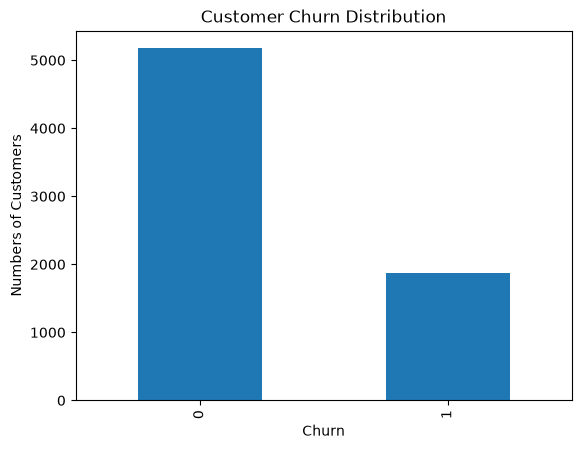

In [8]:
df["Churn Value"].value_counts().plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Numbers of Customers")
plt.show()

In [9]:
pd.crosstab(
    df["Contract"],
    df["Churn Label"],
)

Churn Label,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [10]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

print("Before filling:", df["Total Charges"].isnull().sum())

df["Total Charges"] = df["Total Charges"].fillna(0)

print("After filling:", df["Total Charges"].isnull().sum())

Before filling: 11
After filling: 0


In [12]:
df['Total Charges'].dtypes

dtype('float64')

In [17]:
contract_churn = pd.crosstab(
    df["Contract"],
    df['Churn Label'],
    normalize='index'
)*100
print(contract_churn)

Churn Label            No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


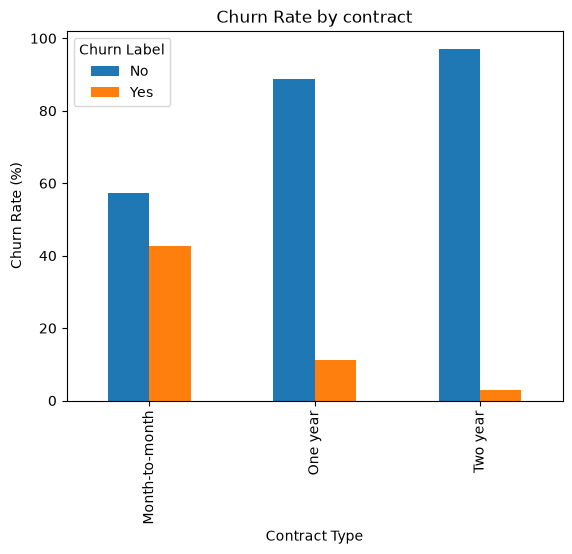

In [19]:
contract_churn.plot(kind='bar')
plt.title("Churn Rate by contract")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.show()

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 34 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [22]:
df.groupby("Churn Label")["Tenure Months"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn Label,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [23]:
df.groupby("Churn Label")["Tenure Months"].mean()

Churn Label
No     37.569965
Yes    17.979133
Name: Tenure Months, dtype: float64

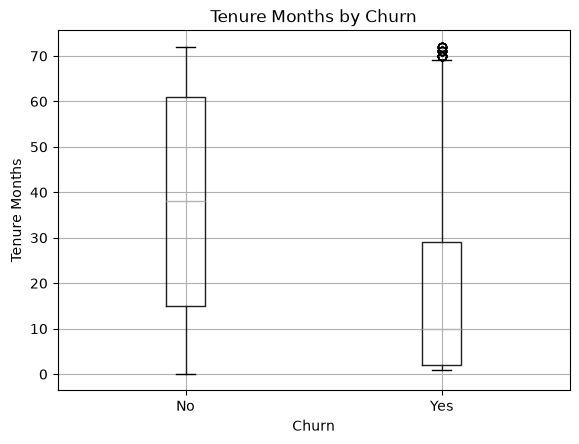

In [25]:
df.boxplot(
    column="Tenure Months",
    by="Churn Label"
)
plt.title("Tenure Months by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure Months")
plt.show()

In [27]:
df.groupby("Churn Label")["Monthly Charges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn Label,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


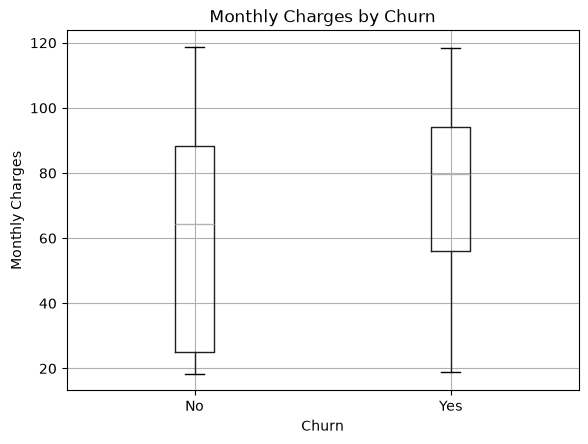

In [30]:
df.boxplot(
    column="Monthly Charges",
    by="Churn Label"
)

plt.title("Monthly Charges by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()  

Churn Label              No        Yes
Internet Service                      
DSL               81.040892  18.959108
Fiber optic       58.107235  41.892765
No                92.595020   7.404980


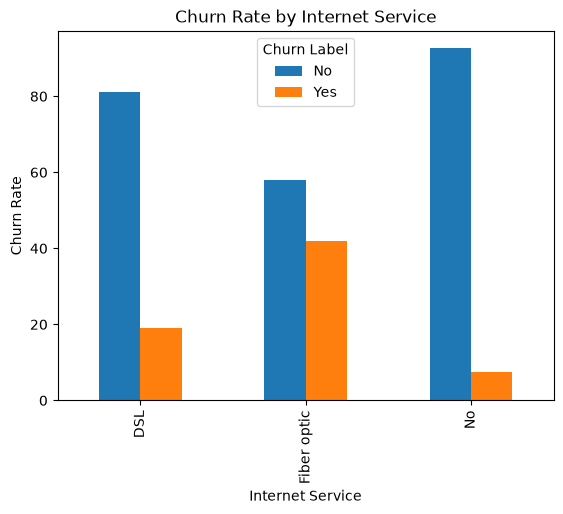

In [39]:
internet_churn = pd.crosstab(
    df["Internet Service"],
    df["Churn Label"],
    normalize='index'
)*100
print(internet_churn)

internet_churn.plot(kind='bar')
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate")
plt.show()

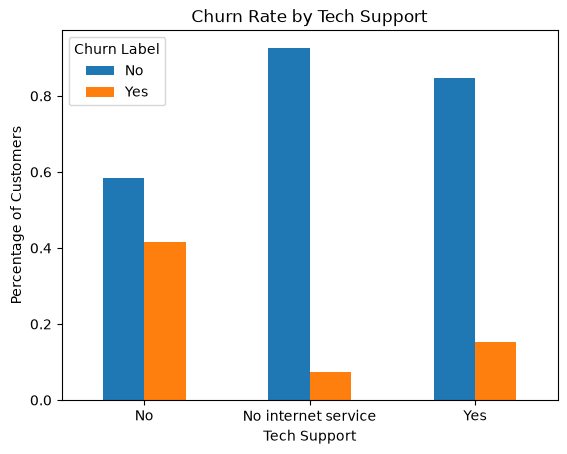

In [47]:
tech_support_churn = pd.crosstab(
    df["Tech Support"],
    df["Churn Label"],
    normalize='index',
)

tech_support_churn.plot(kind='bar')
plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.show()

In [48]:
df["Payment Method"]

0                    Mailed check
1                Electronic check
2                Electronic check
3                Electronic check
4       Bank transfer (automatic)
                  ...            
7038    Bank transfer (automatic)
7039                 Mailed check
7040      Credit card (automatic)
7041             Electronic check
7042    Bank transfer (automatic)
Name: Payment Method, Length: 7043, dtype: str

In [10]:
payment_churn = pd.crosstab(
    df["Payment Method"],
    df["Churn Label"],
    normalize = 'index'
)
print(payment_churn)

Churn Label                      No       Yes
Payment Method                               
Bank transfer (automatic)  0.832902  0.167098
Credit card (automatic)    0.847569  0.152431
Electronic check           0.547146  0.452854
Mailed check               0.808933  0.191067


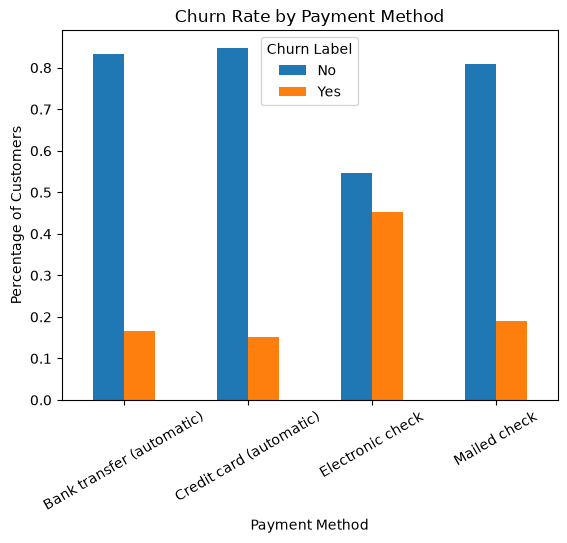

In [12]:
payment_churn.plot(kind='bar')
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=30)
plt.show()